## Step 1: Import all required libraries

In [8]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Suppress warnings for cleaner output
import warnings
warnings.filterwarnings('ignore')

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


## Step 2: Load Data, Check Info, and Drop Unnecessary Columns

In [11]:
# 1. Load the dataset
df = pd.read_csv('netflix_customer_churn.csv')

# 2. Check dataset information (columns, data types, and non-null counts)
print("--- Dataset Information ---")
df.info()

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_id             5000 non-null   object 
 1   age                     5000 non-null   int64  
 2   gender                  5000 non-null   object 
 3   subscription_type       5000 non-null   object 
 4   watch_hours             5000 non-null   float64
 5   last_login_days         5000 non-null   int64  
 6   region                  5000 non-null   object 
 7   device                  5000 non-null   object 
 8   monthly_fee             5000 non-null   float64
 9   churned                 5000 non-null   int64  
 10  payment_method          5000 non-null   object 
 11  number_of_profiles      5000 non-null   int64  
 12  avg_watch_time_per_day  5000 non-null   float64
 13  favorite_genre          5000 non-null   object 
dtypes: float64(3

In [13]:
# 3.check for missing values
print("\n--- Missing Values Check ---")
print(df.isnull().sum())


--- Missing Values Check ---
customer_id               0
age                       0
gender                    0
subscription_type         0
watch_hours               0
last_login_days           0
region                    0
device                    0
monthly_fee               0
churned                   0
payment_method            0
number_of_profiles        0
avg_watch_time_per_day    0
favorite_genre            0
dtype: int64


In [15]:
# 4. Drop the 'customer_id' column as it has no predictive value
df = df.drop(columns=['customer_id'])
print("\n'customer_id' dropped. Remaining columns ready for analysis:")
print(df.columns.tolist())


'customer_id' dropped. Remaining columns ready for analysis:
['age', 'gender', 'subscription_type', 'watch_hours', 'last_login_days', 'region', 'device', 'monthly_fee', 'churned', 'payment_method', 'number_of_profiles', 'avg_watch_time_per_day', 'favorite_genre']


In [17]:
df.head()

,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


## Data Visualization

### 1. Count plot of Churned Customers
- This chart shows the total number of customers who canceled their subscription versus those who stayed.

- It provides a clear starting point to measure the actual size of the cancellation problem.

- A high number of lost customers highlights a direct risk to the company's revenue.

- This baseline confirms we must dig deeper into the data to find out exactly why people are leaving.

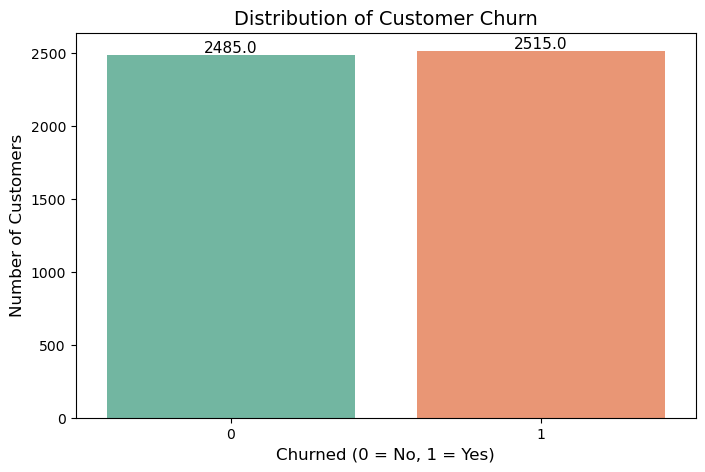

In [23]:
# 1. Count Plot: Distribution of Churned vs. Retained Customers
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='churned', data=df, palette='Set2')

# Adding labels and title
plt.title('Distribution of Customer Churn', fontsize=14)
plt.xlabel('Churned (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

# Adding counts on top of bars for better storytelling
for p in ax.patches:
    ax.annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=11)

plt.show()

### Chart 2: Box Plot of Monthly Fee vs. Churn
- This chart compares the monthly subscription cost between customers who stayed and those who left.

- The "box" shows where the majority of users fall, and the line in the middle is the average price they pay.

- If the box for churned customers is higher, it directly shows that expensive fees are driving people away.

- Businesses can use this insight to adjust their pricing strategy, offer targeted discounts, or create cheaper subscription tiers to keep those at-risk customers.

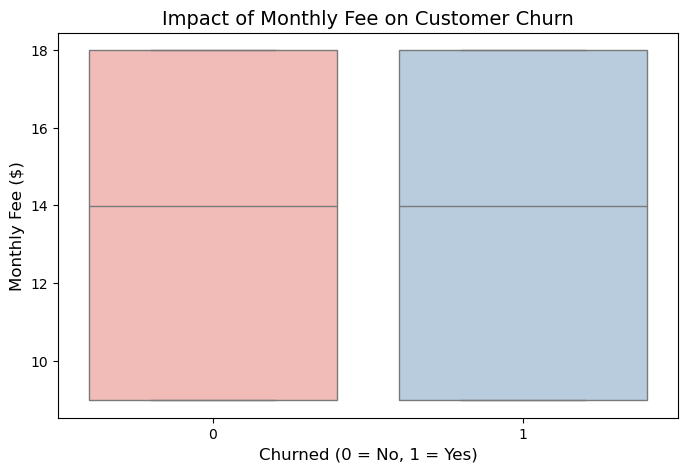

In [26]:
# 2. Box Plot: Does the Monthly Fee affect Churn?
plt.figure(figsize=(8, 5))
sns.boxplot(x='churned', y='monthly_fee', data=df, palette='Pastel1')

# Adding labels and title
plt.title('Impact of Monthly Fee on Customer Churn', fontsize=14)
plt.xlabel('Churned (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Monthly Fee ($)', fontsize=12)

plt.show()

### Chart 3: Correlation Heatmap of Numerical Features
- This heatmap acts like an x-ray for our data, showing how strongly different numerical factors are linked together.

- Red squares show a positive relationship (as one goes up, the other goes up), while blue squares show a negative relationship.

- By looking at the "churned" row or column, we can instantly see which specific numbers (like age or watch hours) have the strongest mathematical connection to a customer leaving.

- This helps business leaders stop guessing and instead focus their retention efforts on the exact metrics that actually influence churn.

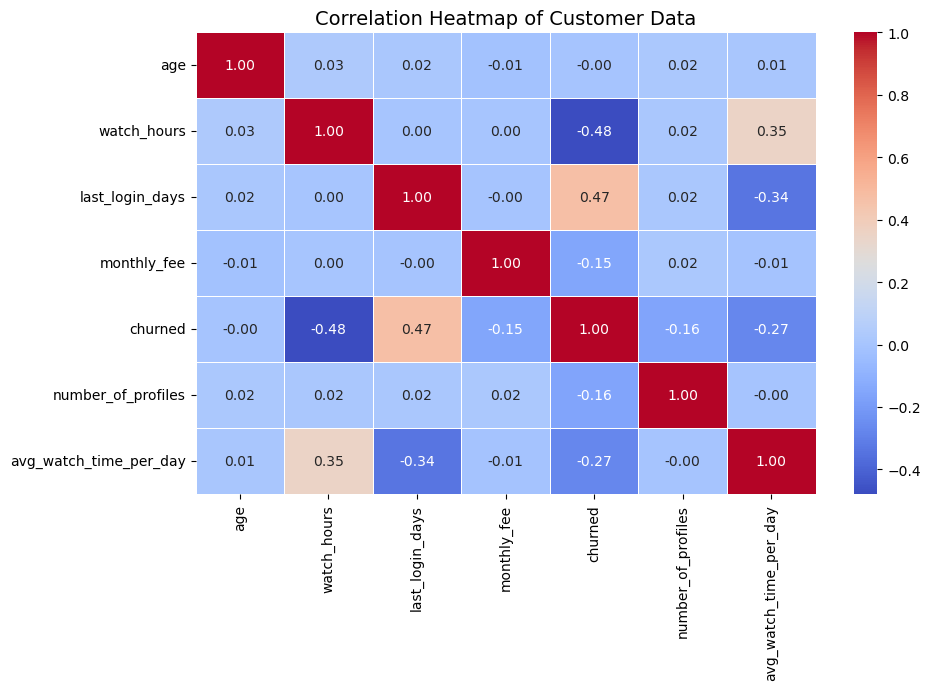

In [29]:
# 3. Heatmap: Correlation between numerical variables
plt.figure(figsize=(10, 6))

# Select only numerical columns for correlation
numerical_df = df.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numerical_df.corr()

# Create the heatmap
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

# Adding title
plt.title('Correlation Heatmap of Customer Data', fontsize=14)

plt.show()

### Chart 4: Pie Chart of Subscription Types
- This chart visualizes the total customer base broken down by their specific subscription plan.

- It immediately highlights which tier (e.g., Basic, Standard, or Premium) is the most popular and drives the most volume.

- Understanding this distribution is crucial; if a huge majority of users are on a single plan, any changes to that plan's features or pricing will drastically impact the company's overall revenue.

- It also sets the stage to investigate later if customers on one specific plan are churning faster than the others.

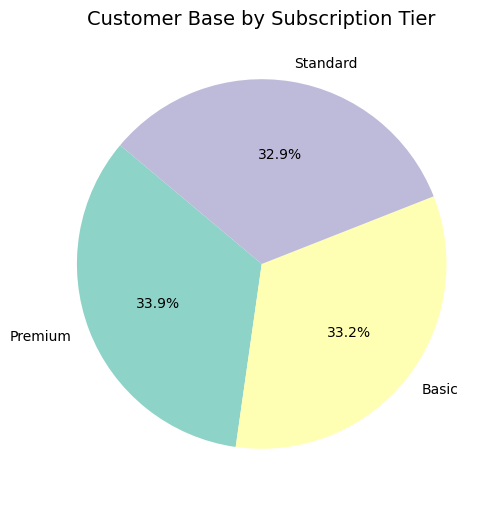

In [39]:
# 4. Pie Chart: Proportion of Subscription Types
plt.figure(figsize=(8, 6))

# Count the number of users in each subscription tier
subscription_counts = df['subscription_type'].value_counts()

# Create the pie chart
plt.pie(subscription_counts, labels=subscription_counts.index, autopct='%1.1f%%', 
        startangle=140, colors=sns.color_palette('Set3'))

# Adding title
plt.title('Customer Base by Subscription Tier', fontsize=14)

plt.show()

### Chart 5: Histogram of Age by Churn Status
- This histogram displays the age profile of the customer base, layered to show exactly how many from each age group canceled their subscription.

- The overlaid curve (KDE line) helps us spot broader age trends, showing where the bulk of our audience sits.

- By looking at the ratio of churned (Yes) to retained (No) within each age bucket, we can immediately identify if a specific generation is leaving at a higher rate.

- If, for example, younger users are churning faster, the business can pivot its content strategy or marketing efforts to better engage that specific demographic.

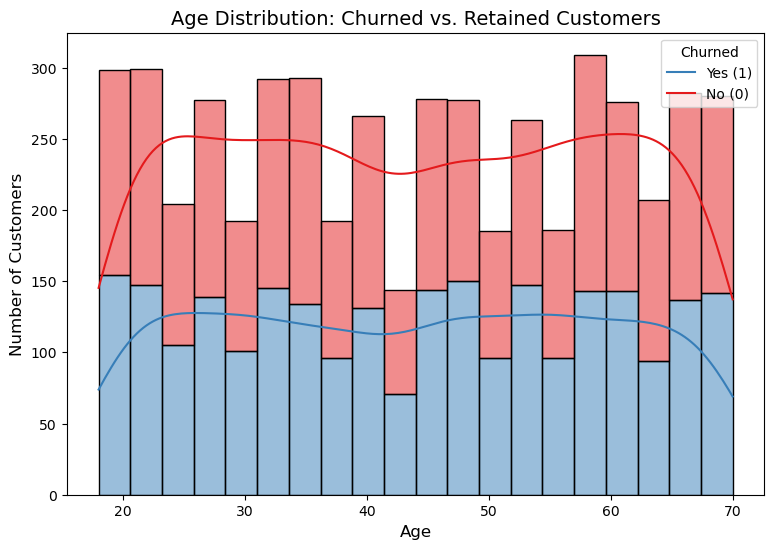

In [42]:
# 5. Histogram: Age Distribution of Customers by Churn Status
plt.figure(figsize=(9, 6))
sns.histplot(data=df, x='age', hue='churned', multiple='stack', palette='Set1', bins=20, kde=True)

# Adding labels, title, and legend
plt.title('Age Distribution: Churned vs. Retained Customers', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)

# Customizing the legend for clarity
plt.legend(title='Churned', labels=['Yes (1)', 'No (0)'])

plt.show()

### 
Chart 6: Bar Chart of Churn by Device Ty
- This chart reveals if customers using certain devices (like Mobile vs. TV) are canceling more often.

- A high churn rate on a specific device strongly suggests a poor user interface or app bugs on that platform.

- The business can use this to direct the tech team to fix app performance issues for the most affected devices.pe

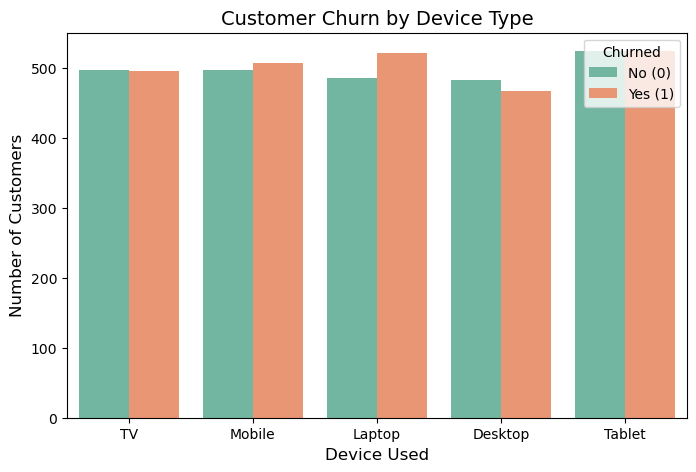

In [45]:
# 6. Bar Chart: Customer Churn by Device Type
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='device', hue='churned', palette='Set2')

# Adding labels, title, and legend
plt.title('Customer Churn by Device Type', fontsize=14)
plt.xlabel('Device Used', fontsize=12)
plt.ylabel('Number of Customers', fontsize=12)
plt.legend(title='Churned', labels=['No (0)', 'Yes (1)'])

plt.show()

### Chart 7: Line Plot of Churn Rate by Last Login Days
- This line chart tracks how the likelihood of cancellation changes based on how long a user has been inactive.

- An upward slope indicates that the longer a customer goes without logging in, the higher their risk of leaving permanently.

- Businesses can use this exact timeline to trigger automated "We miss you" emails or special discounts right before the churn risk spikes.

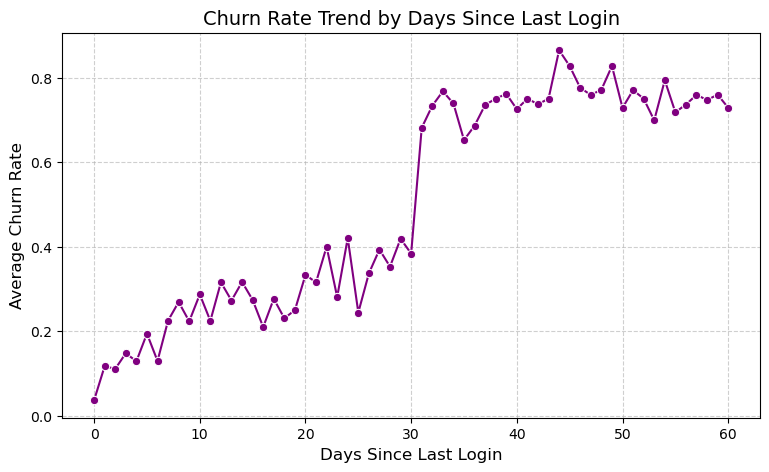

In [48]:
# 7. Line Plot: Trend of Churn Rate based on Last Login Days
plt.figure(figsize=(9, 5))

# Calculate average churn rate for each 'last login day'
churn_trend = df.groupby('last_login_days')['churned'].mean().reset_index()

# Create the line plot
sns.lineplot(data=churn_trend, x='last_login_days', y='churned', marker='o', color='purple')

# Adding labels and title
plt.title('Churn Rate Trend by Days Since Last Login', fontsize=14)
plt.xlabel('Days Since Last Login', fontsize=12)
plt.ylabel('Average Churn Rate', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

### Chart 8: Violin Plot of Average Daily Watch Time
- This chart displays the density and spread of daily viewing habits for both active and canceled users.

- The wider parts of the shape show where the majority of customers cluster in terms of their daily watch hours.

- If canceled users show a bulge at the very bottom (near zero hours), it confirms that low daily engagement is a massive warning sign for churn.

- The business can use this threshold to trigger automatic content recommendations to users whose watch time starts slipping.

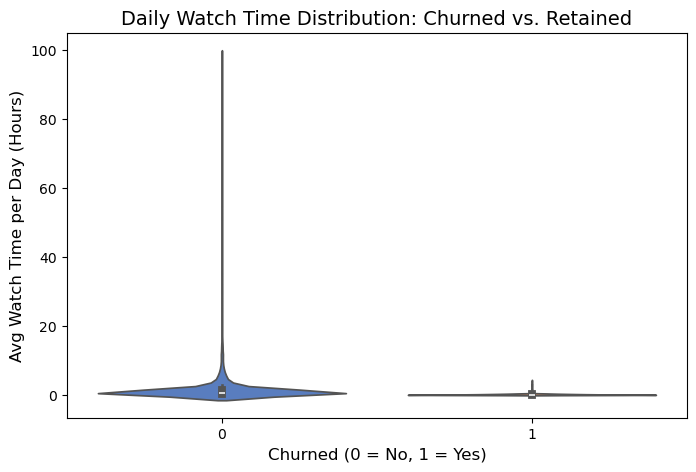

In [55]:
# 8. Violin Plot: Average Watch Time per Day by Churn Status
plt.figure(figsize=(8, 5))
sns.violinplot(data=df, x='churned', y='avg_watch_time_per_day', palette='muted')

# Adding labels and title
plt.title('Daily Watch Time Distribution: Churned vs. Retained', fontsize=14)
plt.xlabel('Churned (0 = No, 1 = Yes)', fontsize=12)
plt.ylabel('Avg Watch Time per Day (Hours)', fontsize=12)

plt.show()

### Chart 9: Scatter Plot of Age vs. Total Watch Hours
- This chart plots every single customer as a dot based on their age and their total watch hours.

- The colors separate the active customers from the ones who canceled.

- It helps us quickly spot clusters—for example, if canceled users (Yes) heavily group at the bottom regardless of their age, it proves that low overall watch time is a universal trigger for churn.

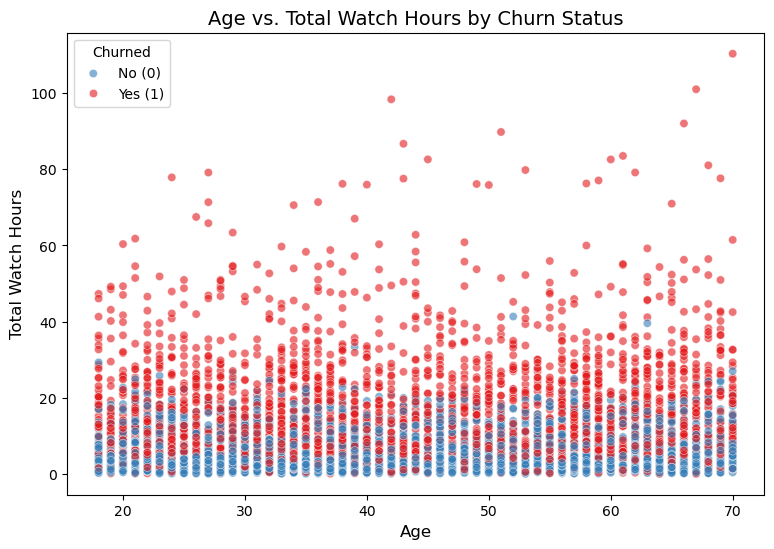

In [59]:
# 9. Scatter Plot: Age vs. Total Watch Hours
plt.figure(figsize=(9, 6))
sns.scatterplot(data=df, x='age', y='watch_hours', hue='churned', palette='Set1', alpha=0.6)

# Adding labels and title
plt.title('Age vs. Total Watch Hours by Churn Status', fontsize=14)
plt.xlabel('Age', fontsize=12)
plt.ylabel('Total Watch Hours', fontsize=12)
plt.legend(title='Churned', labels=['No (0)', 'Yes (1)'])

plt.show()

### Chart 10: Multiple Density Plots (KDE) in One Figure
- This multi-panel density graph provides a dashboard-style comparison of three major numerical factors: Price, Watch Time, and Age.

- By viewing them side-by-side, we can instantly identify which factor has the clearest separation between active and canceled users.

- For example, if the curves for 'Total Watch Hours' are completely separated but the 'Age' curves overlap heavily, it proves to the business that engagement matters far more than demographics when predicting churn.

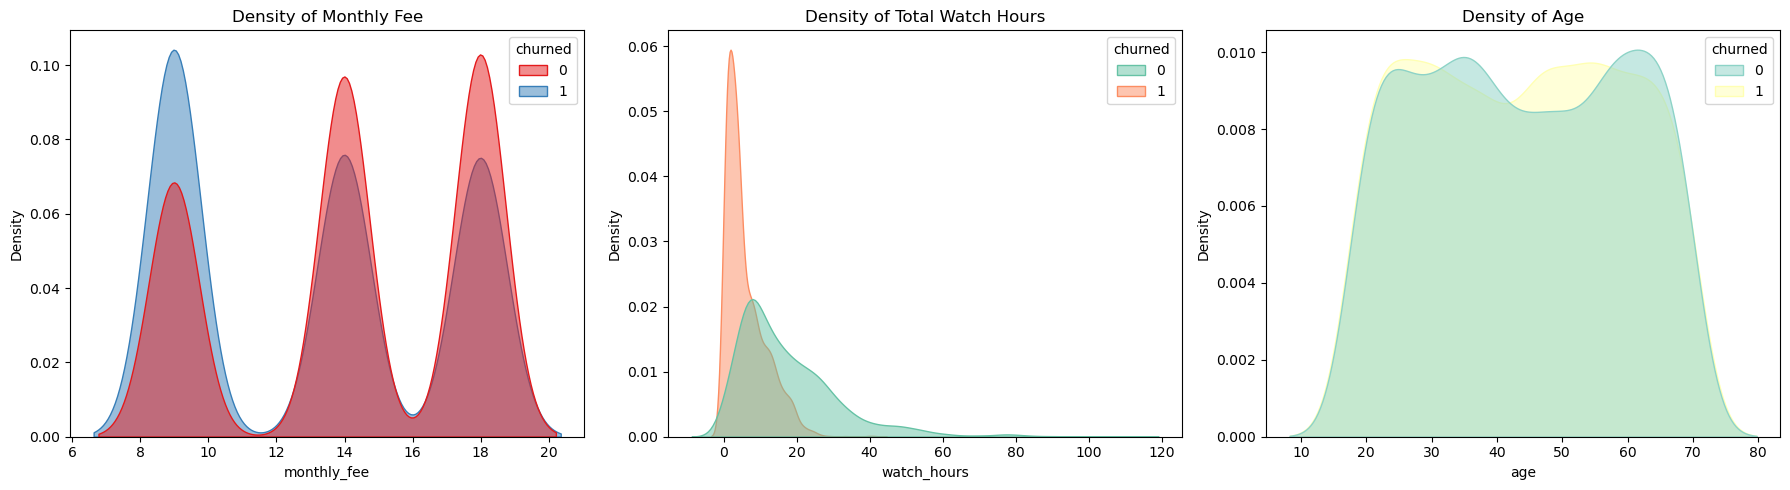

In [62]:
# 10. Multiple Density Plots (KDE) in One Figure
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# KDE for Monthly Fee
sns.kdeplot(data=df, x='monthly_fee', hue='churned', fill=True, ax=axes[0], palette='Set1', alpha=0.5)
axes[0].set_title('Density of Monthly Fee', fontsize=12)

# KDE for Total Watch Hours
sns.kdeplot(data=df, x='watch_hours', hue='churned', fill=True, ax=axes[1], palette='Set2', alpha=0.5)
axes[1].set_title('Density of Total Watch Hours', fontsize=12)

# KDE for Age
sns.kdeplot(data=df, x='age', hue='churned', fill=True, ax=axes[2], palette='Set3', alpha=0.5)
axes[2].set_title('Density of Age', fontsize=12)

plt.tight_layout()
plt.show()